# Supervised Spoken-Language Classification

Compare three manually implemented classifiers (KNN, linear one-vs-rest SVM and MLP) on acoustic features. The evaluation uses a fixed stratified clip-level train/test split and train-fitted standardization/PCA. See [methodology](../docs/methodology.md) and [experimental analysis](../docs/experimental_analysis.md).

## Load the acoustic feature table

Run the preprocessing notebook first or obtain the generated feature CSV. The recorded table contains 655 clips.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FEATURES_CSV = Path("../datasets/features_table.csv")
if not FEATURES_CSV.exists():
    raise FileNotFoundError("features_table.csv not found. Generate it in the Feature Extraction step.")

df = pd.read_csv(FEATURES_CSV)
print("Rows:", len(df))
df.head()

Rows: 655


,language,gender,processed_path,zcr_0_mean,zcr_0_std,rms_0_mean,rms_0_std,spec_centroid_0_mean,spec_centroid_0_std,spec_bandwidth_0_mean,...,chroma_7_mean,chroma_7_std,chroma_8_mean,chroma_8_std,chroma_9_mean,chroma_9_std,chroma_10_mean,chroma_10_std,chroma_11_mean,chroma_11_std
0,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.143043,0.104122,0.060331,0.050995,1944.524575,919.463644,1754.496412,...,0.382088,0.312580,0.421553,0.324034,0.427405,0.323133,0.444297,0.339997,0.432369,0.332017
1,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.127733,0.104457,0.056066,0.045961,1789.767551,960.672971,1720.709832,...,0.351764,0.295726,0.408453,0.304481,0.453395,0.308593,0.490467,0.338070,0.453111,0.328605
2,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.105597,0.085899,0.067285,0.058645,1552.156550,834.720557,1646.997488,...,0.409158,0.309259,0.470213,0.315853,0.499733,0.316083,0.514571,0.342777,0.437941,0.318487
3,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.106475,0.084021,0.058888,0.046811,1620.251206,839.514078,1688.599766,...,0.330343,0.290463,0.402950,0.318937,0.448556,0.315676,0.506503,0.328448,0.498888,0.340772
4,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.114301,0.105571,0.050911,0.043566,1645.476240,971.215322,1680.336391,...,0.372121,0.307793,0.399794,0.305063,0.456234,0.318075,0.515569,0.352761,0.470837,0.327594


## Construct the feature matrix and language labels

Exclude language, gender and file paths from the input features. Encode the four language labels in alphabetical order. The resulting matrix has shape (655, 128).

In [2]:
# Non-feature columns
label_cols = ["language", "gender", "processed_path"]

# All candidate numeric features
feature_cols = [c for c in df.columns if c not in label_cols]

print("Selected features:", len(feature_cols))
print("Example features:", feature_cols[:10])

X = df[feature_cols].values.astype(np.float32)

y_str = df["language"].astype(str).values
classes = np.unique(y_str)
class_to_id = {c: i for i, c in enumerate(classes)}
id_to_class = {i: c for c, i in class_to_id.items()}
y = np.array([class_to_id[v] for v in y_str], dtype=np.int64)

print("X shape:", X.shape)
print("Classes:", classes)

Selected features: 128
Example features: ['zcr_0_mean', 'zcr_0_std', 'rms_0_mean', 'rms_0_std', 'spec_centroid_0_mean', 'spec_centroid_0_std', 'spec_bandwidth_0_mean', 'spec_bandwidth_0_std', 'spec_rolloff_0_mean', 'spec_rolloff_0_std']
X shape: (655, 128)
Classes: ['German' 'Italian' 'Korean' 'Spanish']


## Stratified holdout split

Shuffle within each class with seed 42 and select the ceiling of 20% of each class for testing. This produces 523 training clips and 132 test clips. The split is clip-level; speaker- or audiobook-disjoint evaluation is not enforced.

In [3]:
def stratified_split(X, y, test_size=0.2, seed=42):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []

    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        n_test = int(np.ceil(len(idx) * test_size))
        test_idx.extend(idx[:n_test].tolist())
        train_idx.extend(idx[n_test:].tolist())

    train_idx = np.array(train_idx, dtype=np.int64)
    test_idx = np.array(test_idx, dtype=np.int64)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)

    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = stratified_split(X, y, test_size=0.2, seed=42)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (523, 128) Test: (132, 128)


## Training-only standardization and PCA

Estimate feature means and standard deviations only on training data, then apply them to both partitions. Compute PCA using SVD of the standardized training matrix and retain six components. This avoids fitting these transforms on the test set. No explained-variance threshold or cross-validation is implemented.

In [4]:
def standardize_train_test(X_train, X_test, eps=1e-8):
    mean = X_train.mean(axis=0, keepdims=True)
    std = X_train.std(axis=0, keepdims=True) + eps
    return (X_train - mean) / std, (X_test - mean) / std

X_train_std, X_test_std = standardize_train_test(X_train, X_test)

USE_PCA = True
PCA_K = 6

def pca_fit_fixed_k(X_train_std, k=6):
    # SVD: X = U S Vt -> principal axes are rows of Vt
    U, S, Vt = np.linalg.svd(X_train_std, full_matrices=False)
    components = Vt[:k].T  # (D, k)
    return components.astype(np.float32)

def pca_transform(X_std, components):
    return (X_std @ components).astype(np.float32)

if USE_PCA:
    comps = pca_fit_fixed_k(X_train_std, k=PCA_K)
    X_train_final = pca_transform(X_train_std, comps)
    X_test_final = pca_transform(X_test_std, comps)
    print("PCA enabled:", True, "| Reduced dim:", X_train_final.shape[1])
else:
    X_train_final, X_test_final = X_train_std, X_test_std
    print("PCA enabled:", False)

PCA enabled: True | Reduced dim: 6


## Evaluation metrics

Compute accuracy and the confusion matrix directly from predicted labels. Macro precision, recall and F1 average class-specific metrics equally; weighted metrics weight by test support. Undefined class ratios are set to zero. Rows of each confusion matrix are true classes and columns are predictions.

In [5]:
def confusion_matrix(y_true, y_pred, num_classes):
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)
    for t, p in zip(y_true, y_pred):
        cm[int(t), int(p)] += 1
    return cm

def precision_recall_f1_from_cm(cm):
    tp = np.diag(cm).astype(np.float64)
    fp = (cm.sum(axis=0) - tp).astype(np.float64)
    fn = (cm.sum(axis=1) - tp).astype(np.float64)
    support = cm.sum(axis=1).astype(np.float64)

    precision = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp+fp) != 0)
    recall = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp+fn) != 0)
    f1 = np.divide(2*precision*recall, precision+recall, out=np.zeros_like(tp), where=(precision+recall) != 0)

    macro = {
        "precision": float(np.mean(precision)),
        "recall": float(np.mean(recall)),
        "f1": float(np.mean(f1))
    }

    total = float(np.sum(support)) if np.sum(support) > 0 else 1.0
    weighted = {
        "precision": float(np.sum(precision * support) / total),
        "recall": float(np.sum(recall * support) / total),
        "f1": float(np.sum(f1 * support) / total)
    }

    return macro, weighted

def accuracy(y_true, y_pred):
    return float(np.mean(y_true == y_pred))

def plot_confusion_matrix(cm, class_names, title):
    plt.figure()
    plt.imshow(cm)
    plt.title(title)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
    plt.yticks(range(len(class_names)), class_names)
    plt.colorbar()
    plt.tight_layout()
    plt.show()

def evaluate(y_true, y_pred, class_names, model_name):
    C = len(class_names)
    cm = confusion_matrix(y_true, y_pred, C)
    acc = accuracy(y_true, y_pred)
    macro, weighted = precision_recall_f1_from_cm(cm)

    print(f"\n==================== {model_name} ====================")
    print("Accuracy:", acc)
    print("\nMacro avg:")
    print("  Precision:", macro["precision"])
    print("  Recall   :", macro["recall"])
    print("  F1-score :", macro["f1"])
    print("\nWeighted avg:")
    print("  Precision:", weighted["precision"])
    print("  Recall   :", weighted["recall"])
    print("  F1-score :", weighted["f1"])

    plot_confusion_matrix(cm, class_names, f"{model_name} - Confusion Matrix")

    return {
        "model": model_name,
        "accuracy": acc,
        "precision_macro": macro["precision"],
        "recall_macro": macro["recall"],
        "f1_macro": macro["f1"],
        "precision_weighted": weighted["precision"],
        "recall_weighted": weighted["recall"],
        "f1_weighted": weighted["f1"]
    }

## Classifier implementations

All models use the same six-dimensional representation and the same held-out test clips.

### K-nearest neighbors

Use squared Euclidean distances and majority voting over seven nearest training samples. This nonparametric rule can represent nonlinear local decision boundaries.


==================== KNN (k=7) ====================
Accuracy: 0.9848484848484849

Macro avg:
  Precision: 0.9861111111111112
  Recall   : 0.9852941176470589
  F1-score : 0.9852813852813853

Weighted avg:
  Precision: 0.9856902356902357
  Recall   : 0.9848484848484849
  F1-score : 0.9848353666535485


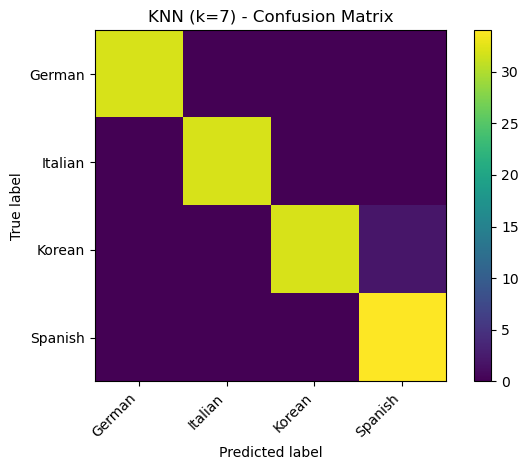

In [6]:
def knn_predict(X_train, y_train, X_test, k=7):
    """
    Predict using KNN (Euclidean distance).
    """
    y_pred = np.zeros((X_test.shape[0],), dtype=np.int64)

    for i in range(X_test.shape[0]):
        # Compute squared Euclidean distances to all training samples
        dists = np.sum((X_train - X_test[i]) ** 2, axis=1)

        # Indices of k nearest neighbors
        nn_idx = np.argpartition(dists, k)[:k]
        nn_labels = y_train[nn_idx]

        # Majority vote
        vals, cnt = np.unique(nn_labels, return_counts=True)
        y_pred[i] = vals[np.argmax(cnt)]

    return y_pred
knn_k = 7
y_pred_knn = knn_predict(X_train_final, y_train, X_test_final, k=knn_k)
res_knn = evaluate(y_test, y_pred_knn, classes, f"KNN (k={knn_k})")

### Linear one-vs-rest support vector machine

Train four binary classifiers with per-example SGD on hinge loss and L2 weight regularization. Learning rate 0.002, regularization 0.01, 25 epochs, seed 42. Predict the class with the highest linear score.


==================== Linear SVM  ====================
Accuracy: 0.946969696969697

Macro avg:
  Precision: 0.9494266994266994
  Recall   : 0.9471507352941176
  F1-score : 0.9471759809198682

Weighted avg:
  Precision: 0.9483533119896757
  Recall   : 0.946969696969697
  F1-score : 0.9465535097849168


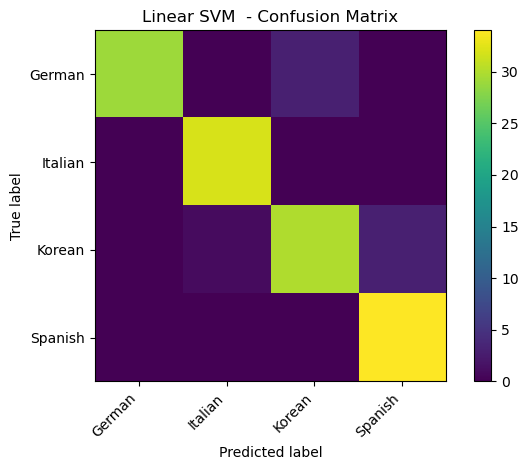

In [7]:
def svm_ovr_train_sgd(X, y, num_classes, lr=0.01, reg=1e-4, epochs=30, seed=42):
    """
    Train One-vs-Rest linear SVM with SGD on hinge loss.
    Returns W (C x D) and b (C,).
    """
    rng = np.random.default_rng(seed)
    N, D = X.shape
    W = np.zeros((num_classes, D), dtype=np.float32)
    b = np.zeros((num_classes,), dtype=np.float32)

    for c in range(num_classes):
        # Binary labels: +1 for class c, -1 for others
        yc = np.where(y == c, 1.0, -1.0).astype(np.float32)

        w = np.zeros((D,), dtype=np.float32)
        bb = 0.0

        for ep in range(epochs):
            idx = rng.permutation(N)
            for i in idx:
                xi = X[i]
                yi = yc[i]
                score = np.dot(w, xi) + bb
                margin = yi * score

                # Hinge loss gradient
                if margin < 1.0:
                    # w := w - lr*(reg*w - yi*xi)
                    w = w - lr * (reg * w - yi * xi)
                    bb = bb + lr * yi
                else:
                    # Only regularization term
                    w = w - lr * (reg * w)

        W[c] = w
        b[c] = bb

    return W, b

def svm_ovr_predict(X, W, b):
    """
    Predict class = argmax_c (w_c^T x + b_c)
    """
    scores = X @ W.T + b.reshape(1, -1)
    return np.argmax(scores, axis=1).astype(np.int64)

W_svm, b_svm = svm_ovr_train_sgd(
    X_train_final, y_train,
    num_classes=len(classes),
    lr=0.002,
    reg=1e-2,
    epochs=25,
    seed=42
)

y_pred_svm = svm_ovr_predict(X_test_final, W_svm, b_svm)
res_svm = evaluate(y_test, y_pred_svm, classes, "Linear SVM ")



### Multi-layer perceptron

Use one hidden layer of 16 ReLU units, softmax outputs and manual mini-batch backpropagation with cross-entropy and L2 weight regularization. The actual training call uses 40 epochs, batch size 64, learning rate 0.01 and regularization 0.02, with seed 42. The recorded final training accuracy is 0.9790.

Epoch 10/40 - Train Acc: 0.9312
Epoch 20/40 - Train Acc: 0.9713
Epoch 30/40 - Train Acc: 0.9790
Epoch 40/40 - Train Acc: 0.9790

====================  MLP  ====================
Accuracy: 0.9545454545454546

Macro avg:
  Precision: 0.955422794117647
  Recall   : 0.955422794117647
  F1-score : 0.955422794117647

Weighted avg:
  Precision: 0.9545454545454546
  Recall   : 0.9545454545454546
  F1-score : 0.9545454545454546


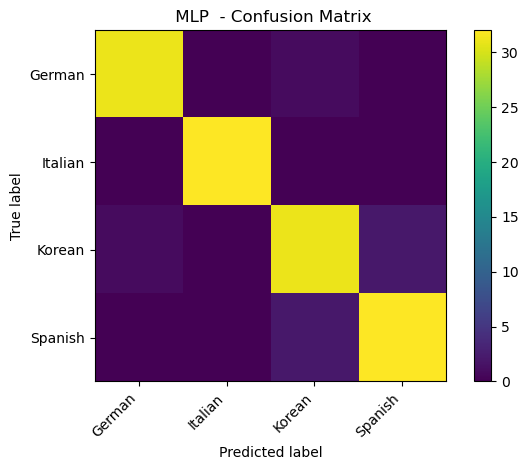

In [11]:
def one_hot(y, num_classes):
    Y = np.zeros((len(y), num_classes), dtype=np.float32)
    Y[np.arange(len(y)), y] = 1.0
    return Y

def softmax(logits):
    z = logits - np.max(logits, axis=1, keepdims=True)
    expz = np.exp(z)
    return expz / np.sum(expz, axis=1, keepdims=True)

def relu(x):
    return np.maximum(0, x)

def relu_grad(x):
    return (x > 0).astype(np.float32)

def mlp_train(X, y, num_classes, hidden=128, lr=1e-2, epochs=60, batch_size=32, reg=1e-4, seed=42):
    """
    Train a 1-hidden-layer MLP manually using mini-batch gradient descent.
    Returns parameters (W1, b1, W2, b2).
    """
    rng = np.random.default_rng(seed)
    N, D = X.shape

    # initialization for ReLU
    W1 = (rng.standard_normal((D, hidden)).astype(np.float32)) * np.sqrt(2.0 / D)
    b1 = np.zeros((hidden,), dtype=np.float32)
    W2 = (rng.standard_normal((hidden, num_classes)).astype(np.float32)) * np.sqrt(2.0 / hidden)
    b2 = np.zeros((num_classes,), dtype=np.float32)

    Y = one_hot(y, num_classes)

    for ep in range(epochs):
        idx = rng.permutation(N)
        Xs = X[idx]
        Ys = Y[idx]

        # Mini-batches
        for start in range(0, N, batch_size):
            end = min(start + batch_size, N)
            xb = Xs[start:end]
            yb = Ys[start:end]
            m = xb.shape[0]

            # Forward
            z1 = xb @ W1 + b1
            a1 = relu(z1)
            logits = a1 @ W2 + b2
            probs = softmax(logits)

            # Loss gradient (softmax + cross-entropy)
            dlogits = (probs - yb) / m  # (m, C)

            # Backprop
            dW2 = a1.T @ dlogits + reg * W2
            db2 = np.sum(dlogits, axis=0)

            da1 = dlogits @ W2.T
            dz1 = da1 * relu_grad(z1)

            dW1 = xb.T @ dz1 + reg * W1
            db1 = np.sum(dz1, axis=0)

            # Update
            W1 -= lr * dW1
            b1 -= lr * db1
            W2 -= lr * dW2
            b2 -= lr * db2

        if (ep + 1) % 10 == 0:
            # Compute training accuracy quickly
            train_pred = mlp_predict(X, W1, b1, W2, b2)
            train_acc = accuracy(y, train_pred)
            print(f"Epoch {ep+1}/{epochs} - Train Acc: {train_acc:.4f}")

    return W1, b1, W2, b2

def mlp_predict(X, W1, b1, W2, b2):
    z1 = X @ W1 + b1
    a1 = relu(z1)
    logits = a1 @ W2 + b2
    probs = softmax(logits)
    return np.argmax(probs, axis=1).astype(np.int64)


W1, b1, W2, b2 = mlp_train(
    X_train_final, y_train,
    num_classes=len(classes),
    hidden=16,
    lr=0.01,
    epochs=40,
    batch_size=64,
    reg=2e-2,
    seed=42
)

y_pred_mlp = mlp_predict(X_test_final, W1, b1, W2, b2)
res_mlp = evaluate(y_test, y_pred_mlp, classes, " MLP ")

## Compare test performance

KNN correctly classifies 130/132 clips, MLP 126/132 and linear SVM 125/132. KNN leads on accuracy, macro F1 and weighted F1. Local class structure in the standardized PCA space is a plausible explanation, not a causal finding. No independent validation or repeated-split comparison is available.

In [9]:
results = pd.DataFrame([res_knn, res_svm, res_mlp]).sort_values("accuracy", ascending=False)
results

,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,KNN (k=7),0.984848,0.986111,0.985294,0.985281,0.985690,0.984848,0.984835
2,MLP,0.954545,0.955423,0.955423,0.955423,0.954545,0.954545,0.954545
1,Linear SVM,0.946970,0.949427,0.947151,0.947176,0.948353,0.946970,0.946554


## Export classification metrics

Save the comparison table for the evaluation notebook.

In [10]:
from pathlib import Path
out_csv = Path("../results/classification_results_summary.csv")
results.to_csv(out_csv, index=False)
print("Saved:", out_csv.resolve())


Saved: C:\Users\Farzam\MLProject\edited\classification_results_summary.csv


## Conclusion

| Model | Accuracy | Macro F1 | Weighted F1 |
|---|---:|---:|---:|
| KNN (k=7) | 0.984848 | 0.985281 | 0.984835 |
| MLP | 0.954545 | 0.955423 | 0.954545 |
| Linear SVM | 0.946970 | 0.947176 | 0.946554 |

KNN is the strongest classifier on the recorded split. The relatively high results across all three models support the usefulness of the acoustic representation on this corpus. They do not establish speaker-independent generalization: multiple clips from the same audiobook or narrator may occur on both sides of the split. No external dataset or repeated-seed evaluation is included. The comparison does not isolate the contribution of any individual feature group.